# 05 — Démo Live : Compression Adaptative en Temps Réel (outil de présentation)

⚠️ **Important à comprendre** : ce notebook est un **outil de démonstration/communication**


In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, pickle, zlib, heapq, time
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output

BASE = '/content/drive/MyDrive/Projet_Compression_WESAD'

with open(f'{BASE}/1_Data_Raw/WESAD/S2/S2.pkl', 'rb') as f:
    s2_data = pickle.load(f, encoding='latin1')

print("Chargé.")


Mounted at /content/drive
Chargé.


## Fonctions (reprises des notebooks précédents)

In [2]:
def compress_rle(segment, precision=3):
    arr = np.round(np.asarray(segment, dtype=np.float32), precision)
    values, counts = [], []
    prev, count = arr[0], 1
    for x in arr[1:]:
        if x == prev: count += 1
        else:
            values.append(prev); counts.append(count); prev, count = x, 1
    values.append(prev); counts.append(count)
    values = np.array(values, dtype=np.float32); counts = np.array(counts, dtype=np.uint16)
    return zlib.compress(values.tobytes() + counts.tobytes()), len(values)

def decompress_rle(compressed, n_pairs):
    raw = zlib.decompress(compressed)
    values = np.frombuffer(raw[:n_pairs*4], dtype=np.float32)
    counts = np.frombuffer(raw[n_pairs*4:], dtype=np.uint16)
    return np.repeat(values, counts)

def compress_lz77(segment):
    return zlib.compress(np.asarray(segment, dtype=np.float32).tobytes(), level=9)

def decompress_lz77(compressed):
    return np.frombuffer(zlib.decompress(compressed), dtype=np.float32)

def build_huffman_codebook(symbols):
    freq = Counter(symbols)
    heap = [[weight, [symbol, ""]] for symbol, weight in freq.items()]
    heapq.heapify(heap)
    if len(heap) == 1:
        return {heap[0][1][0]: "0"}
    while len(heap) > 1:
        lo = heapq.heappop(heap); hi = heapq.heappop(heap)
        for pair in lo[1:]: pair[1] = '0' + pair[1]
        for pair in hi[1:]: pair[1] = '1' + pair[1]
        heapq.heappush(heap, [lo[0] + hi[0]] + lo[1:] + hi[1:])
    return {s: c for s, c in heap[0][1:]}

def compress_huffman(segment, precision=3):
    arr = np.round(np.asarray(segment, dtype=np.float32), precision)
    symbols = arr.tolist()
    codebook = build_huffman_codebook(symbols)
    bitstring = ''.join(codebook[s] for s in symbols)
    padding = (8 - len(bitstring) % 8) % 8
    bitstring += '0' * padding
    encoded = bytearray(int(bitstring[i:i+8], 2) for i in range(0, len(bitstring), 8))
    payload = {'codebook': pickle.dumps(codebook), 'data': bytes(encoded),
               'padding': padding, 'n_symbols': len(symbols)}
    return zlib.compress(pickle.dumps(payload))

def decompress_huffman(compressed):
    payload = pickle.loads(zlib.decompress(compressed))
    reverse_codebook = {v: k for k, v in pickle.loads(payload['codebook']).items()}
    bitstring = ''.join(f'{byte:08b}' for byte in payload['data'])
    if payload['padding']: bitstring = bitstring[:-payload['padding']]
    symbols, current = [], ''
    for bit in bitstring:
        current += bit
        if current in reverse_codebook:
            symbols.append(reverse_codebook[current]); current = ''
    return np.array(symbols[:payload['n_symbols']], dtype=np.float32)

def compressed_size_proxy(segment, precision=3):
    arr = np.round(np.asarray(segment, dtype=np.float32), precision)
    return len(zlib.compress(arr.tobytes(), level=1))

def compress_delta(segment):
    arr = np.asarray(segment, dtype=np.float32)
    payload = np.concatenate(([arr[0]], np.diff(arr))).astype(np.float32)
    return zlib.compress(payload.tobytes())

def decompress_delta(compressed):
    payload = np.frombuffer(zlib.decompress(compressed), dtype=np.float32)
    first, delta = payload[0], payload[1:]
    return np.concatenate(([first], first + np.cumsum(delta)))

from scipy.fftpack import dct, idct
def compress_dct(segment, keep_ratio=0.2):
    arr = np.asarray(segment, dtype=np.float32)
    coeffs = dct(arr, norm='ortho')
    n_keep = max(1, int(len(coeffs) * keep_ratio))
    truncated = np.zeros_like(coeffs)
    idx = np.argsort(np.abs(coeffs))[-n_keep:]
    truncated[idx] = coeffs[idx]
    return zlib.compress(truncated.astype(np.float32).tobytes()), len(coeffs)

def decompress_dct(compressed, n_total):
    coeffs = np.frombuffer(zlib.decompress(compressed), dtype=np.float32)
    return idct(coeffs, norm='ortho')

import pywt
def compress_dwt(segment, wavelet='db4', level=3, threshold_ratio=0.1):
    arr = np.asarray(segment, dtype=np.float32)
    max_level = pywt.dwt_max_level(len(arr), pywt.Wavelet(wavelet).dec_len)
    eff_level = min(level, max_level)
    if eff_level < 1:
        return zlib.compress(arr.tobytes()), None
    coeffs = pywt.wavedec(arr, wavelet, level=eff_level)
    if len(coeffs) > 1:
        detail_flat = np.concatenate([c.flatten() for c in coeffs[1:]])
        threshold = threshold_ratio * np.max(np.abs(detail_flat)) if len(detail_flat) else 0
        coeffs_thresh = [coeffs[0]] + [pywt.threshold(c, threshold, mode='soft') for c in coeffs[1:]]
    else:
        coeffs_thresh = coeffs
    shapes = [c.shape[0] for c in coeffs_thresh]
    out = np.concatenate([c.flatten() for c in coeffs_thresh]).astype(np.float32)
    return zlib.compress(out.tobytes()), shapes

def decompress_dwt(compressed, shapes, wavelet='db4'):
    if shapes is None:
        return np.frombuffer(zlib.decompress(compressed), dtype=np.float32)
    flat = np.frombuffer(zlib.decompress(compressed), dtype=np.float32)
    coeffs, idx = [], 0
    for size in shapes:
        coeffs.append(flat[idx:idx+size]); idx += size
    return pywt.waverec(coeffs, wavelet)

def apply_algo(algo, segment):
    if algo == 'RLE': c, n = compress_rle(segment); return c, decompress_rle(c, n)
    elif algo == 'LZ77': c = compress_lz77(segment); return c, decompress_lz77(c)
    elif algo == 'Huffman': c = compress_huffman(segment); return c, decompress_huffman(c)
    elif algo == 'Delta': c = compress_delta(segment); return c, decompress_delta(c)
    elif algo == 'DCT': c, n = compress_dct(segment); return c, decompress_dct(c, n)
    elif algo == 'DWT': c, shapes = compress_dwt(segment); return c, decompress_dwt(c, shapes)
    raise ValueError(algo)

from scipy.stats import entropy as scipy_entropy
def compute_features(segment):
    seg = np.asarray(segment, dtype=float)
    variance = float(np.var(seg))
    hist, _ = np.histogram(seg, bins=20, density=True)
    hist = hist[hist > 0]
    ent = float(scipy_entropy(hist)) if len(hist) > 0 else 0.0
    return {'variance': variance, 'entropy': ent}

def multi_criteria_selector(features, size_bytes, var_ref, size_ref, prev_features=None,
                             rel_size_threshold=0.3, rel_sim_threshold=0.3,
                             entropy_threshold_low=1.0, entropy_threshold_mid=1.8,
                             entropy_threshold_high=2.5):
    # CORRECTIF : taille et similarite en RELATIF au profil du capteur (var_ref, size_ref),
    # comme dans le notebook 03 -- sinon un seuil unique est incomparable entre chest et wrist.
    rel_size = size_bytes / size_ref
    if rel_size < rel_size_threshold:
        return 'LZ77'
    if prev_features is not None:
        rel_diff = abs(features['variance'] - prev_features['variance']) / var_ref
        if rel_diff < rel_sim_threshold:
            return 'Delta'
    e = features['entropy']
    t1, t2, t3 = sorted([entropy_threshold_low, entropy_threshold_mid, entropy_threshold_high])
    if e < t1:
        return 'RLE'
    elif e < t2:
        return 'Huffman'
    elif e < t3:
        return 'DWT'
    else:
        return 'DCT'

import json as _json
_thresholds_path = f'{BASE}/4_Results/best_thresholds.json'
if os.path.exists(_thresholds_path):
    with open(_thresholds_path) as f:
        BEST_THRESHOLDS = _json.load(f)
    print("Seuils chargés depuis best_thresholds.json :", BEST_THRESHOLDS)
else:
    BEST_THRESHOLDS = dict(rel_size_threshold=0.25, entropy_threshold_low=1.457,
                            entropy_threshold_mid=2.104, entropy_threshold_high=2.321,
                            rel_sim_threshold=0.2)
    print("⚠️ best_thresholds.json introuvable, valeur de secours utilisée :", BEST_THRESHOLDS)

print("Prêt.")


Seuils chargés depuis best_thresholds.json : {'rel_size_threshold': 0.9542739512569471, 'entropy_threshold_low': 2.060353353434931, 'entropy_threshold_mid': 2.2848028476023443, 'entropy_threshold_high': 2.5022319635077004, 'rel_sim_threshold': 0.11538598991772761}
Prêt.


## Démo live : signal ECG, bloc par bloc

Simule un flux : traite le signal ECG bloc de 5s par bloc de 5s, comme le ferait un capteur
IoT avant d'envoyer vers le cloud. Affiche à chaque bloc : le signal original vs reconstruit,
le volume cumulé brut vs compressé, et l'algorithme choisi.

Règle `N_BLOCS_DEMO` pour la durée de la démo (chaque bloc = ~1-2 secondes d'affichage).

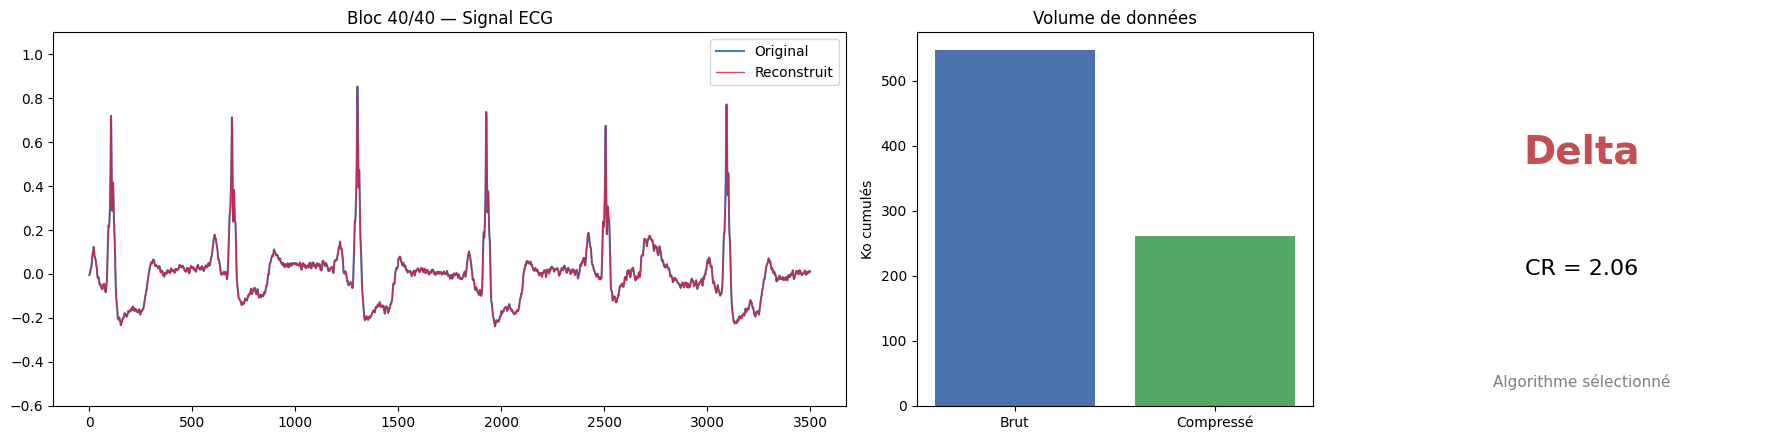


Démo terminée. Volume brut total : 546.9 Ko -> compressé : 260.3 Ko
Gain global : 52.4%


In [3]:
ecg_raw = s2_data['signal']['chest']['ECG'].flatten()
fs = 700
win_len = fs * 5  # blocs de 5 secondes
n_blocs_total = len(ecg_raw) // win_len

N_BLOCS_DEMO = 40       # nombre de blocs à jouer pendant la démo (ajuste selon le temps dispo)
PAUSE_SECONDES = 0.4    # vitesse de la démo

volume_brut_cumule = 0
volume_compresse_cumule = 0
prev_feat = None
historique_ratio = []

# reference du capteur ECG (mediane sur ses propres segments), necessaire pour les
# seuils RELATIFS du selecteur corrige
_ref_segs = [ecg_raw[i*win_len:(i+1)*win_len] for i in range(n_blocs_total)]
_ref_feats = [compute_features(s) for s in _ref_segs[:100]]
var_ref = float(np.median([f['variance'] for f in _ref_feats])) or 1e-9
size_ref = float(np.median([compressed_size_proxy(s) for s in _ref_segs[:100]])) or 1e-9

for i in range(min(N_BLOCS_DEMO, n_blocs_total)):
    seg = ecg_raw[i*win_len:(i+1)*win_len]
    feat = compute_features(seg)
    raw_size_bytes = np.asarray(seg, dtype=np.float32).nbytes  # taille RÉELLEMENT brute (non compressée)
    size_bytes = compressed_size_proxy(seg)  # utilisé UNIQUEMENT comme critère taille pour le sélecteur
    algo = multi_criteria_selector(feat, size_bytes, var_ref, size_ref, prev_feat, **BEST_THRESHOLDS)
    c, rec = apply_algo(algo, seg)
    rec = np.asarray(rec)[:len(seg)]

    volume_brut_cumule += raw_size_bytes       # CORRIGÉ : vraie taille brute, pas le proxy compressé
    volume_compresse_cumule += len(c)
    ratio_instant = raw_size_bytes / len(c)    # CORRIGÉ
    historique_ratio.append(ratio_instant)
    prev_feat = feat

    clear_output(wait=True)
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), gridspec_kw={'width_ratios': [2, 1, 1]})

    # Zone 1 : signal original vs reconstruit
    axes[0].plot(seg, color='steelblue', label='Original', linewidth=1.5)
    axes[0].plot(rec, color='crimson', label='Reconstruit', linewidth=1, alpha=0.8)
    axes[0].set_title(f"Bloc {i+1}/{min(N_BLOCS_DEMO, n_blocs_total)} — Signal ECG")
    axes[0].legend(loc='upper right')
    axes[0].set_ylim(-0.6, 1.1)

    # Zone 2 : volumes cumulés
    axes[1].bar(['Brut', 'Compressé'],
                [volume_brut_cumule / 1024, volume_compresse_cumule / 1024],
                color=['#4C72B0', '#55A868'])
    axes[1].set_ylabel('Ko cumulés')
    axes[1].set_title('Volume de données')

    # Zone 3 : algorithme choisi + ratio instantané
    axes[2].axis('off')
    axes[2].text(0.5, 0.65, algo, fontsize=28, fontweight='bold', ha='center', color='#C44E52')
    axes[2].text(0.5, 0.35, f"CR = {ratio_instant:.2f}", fontsize=16, ha='center')
    axes[2].text(0.5, 0.05, "Algorithme sélectionné", fontsize=11, ha='center', color='gray')

    plt.tight_layout()
    plt.show()
    time.sleep(PAUSE_SECONDES)

print(f"\nDémo terminée. Volume brut total : {volume_brut_cumule/1024:.1f} Ko -> compressé : {volume_compresse_cumule/1024:.1f} Ko")
print(f"Gain global : {100*(1 - volume_compresse_cumule/volume_brut_cumule):.1f}%")
